In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")      # Titanic (Kaggle train.csv) - keep it in the same folder as this notebook
print("Rows:", df.shape[0], " Columns:", df.shape[1])
df.head()
print("Categorical:", df.select_dtypes(exclude=np.number).columns.tolist())
print("Numerical:  ", df.select_dtypes(include=np.number).columns.tolist())

Rows: 891  Columns: 12
Categorical: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']
Numerical:   ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


In [3]:
num_col = "Fare"
stratify_col = "Pclass"
cluster_col = "Embarked"

N = len(df)
n = max(1, int(0.20 * N))
population_mean = df[num_col].mean()
print("N =", N, " n =", n, " Population mean =", round(population_mean, 3))

N = 891  n = 178  Population mean = 32.204


In [4]:
srs_sample = df.sample(n=n, random_state=42)
print("SRS sample size:", len(srs_sample))
display(srs_sample.head())
display(df.sample(n=n, random_state=100).head())   # different seed -> different rows

SRS sample size: 178


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
709,710,1,3,"Moubarek, Master. Halim Gonios (""William George"")",male,NaN,1,1,2661,15.2458,NaN,C
439,440,0,2,"Kvillner, Mr. Johan Henrik Johannesson",male,31.0,0,0,C.A. 18723,10.5000,NaN,S
840,841,0,3,"Alhomaki, Mr. Ilmari Rudolf",male,20.0,0,0,SOTON/O2 3101287,7.9250,NaN,S
720,721,1,2,"Harper, Miss. Annie Jessie ""Nina""",female,6.0,0,1,248727,33.0000,NaN,S
39,40,1,3,"Nicola-Yarred, Miss. Jamila",female,14.0,1,0,2651,11.2417,NaN,C


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
205,206,0,3,"Strom, Miss. Telma Matilda",female,2.0,0,1,347054,10.4625,G6,S
44,45,1,3,"Devaney, Miss. Margaret Delia",female,19.0,0,0,330958,7.8792,NaN,Q
821,822,1,3,"Lulic, Mr. Nikola",male,27.0,0,0,315098,8.6625,NaN,S
458,459,1,2,"Toomey, Miss. Ellen",female,50.0,0,0,F.C.C. 13531,10.5000,NaN,S
795,796,0,2,"Otter, Mr. Richard",male,39.0,0,0,28213,13.0000,NaN,S


Pclass
3    491
1    216
2    184
Name: count, dtype: int64


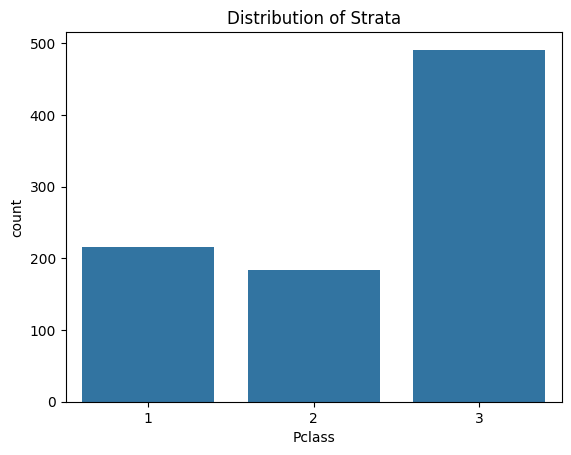

Stratified sample size: 178
        Population %  Sample %
Pclass                        
3              55.11     55.06
1              24.24     24.16
2              20.65     20.79


In [5]:
print(df[stratify_col].value_counts())
sns.countplot(data=df, x=stratify_col); 
plt.title("Distribution of Strata"); 
plt.show()

strat_sample = df.groupby(stratify_col, group_keys=False).sample(frac=n/N, random_state=42)
print("Stratified sample size:", len(strat_sample))
strat_prop = pd.DataFrame({
    "Population %": df[stratify_col].value_counts(normalize=True) * 100,
    "Sample %": strat_sample[stratify_col].value_counts(normalize=True) * 100
}).round(2)
print(strat_prop)

In [6]:
clusters = df[cluster_col].dropna().unique()
k = max(1, int(0.30 * len(clusters)))
rng = np.random.default_rng(42)
selected = rng.choice(clusters, size=k, replace=False)
print("Total clusters:", len(clusters), " Selected:", list(selected))
cluster_sample = df[df[cluster_col].isin(selected)].copy()
print("Cluster sample size:", len(cluster_sample))

Total clusters: 3  Selected: ['S']
Cluster sample size: 644


               Sample Size  Sample Mean  Difference from Population Mean
Simple Random          178       30.763                           -1.441
Stratified             178       30.929                           -1.276
Cluster                644       27.080                           -5.124


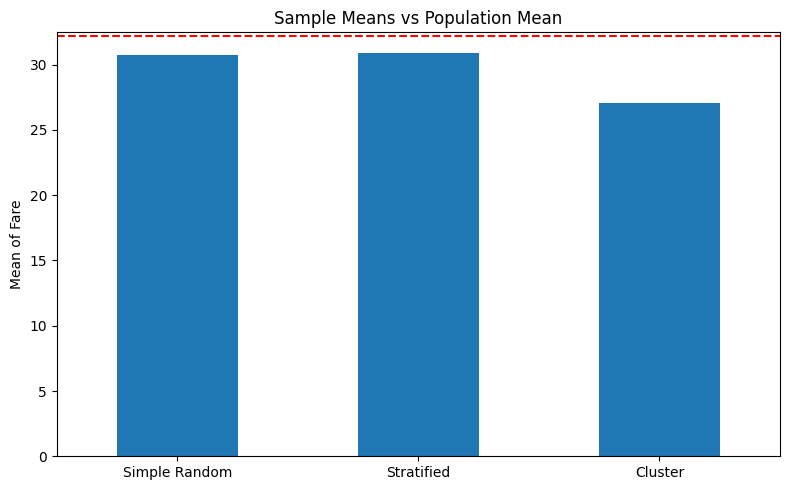

In [7]:
samples = {
    "Simple Random": srs_sample,
    "Stratified": strat_sample,
    "Cluster": cluster_sample
}

comparison = pd.DataFrame({
    "Sample Size": [len(s) for s in samples.values()],
    "Sample Mean": [s[num_col].mean() for s in samples.values()]
}, index=samples.keys())

comparison["Difference from Population Mean"] = comparison["Sample Mean"] - population_mean
print(comparison.round(3))

plt.figure(figsize=(8, 5))
comparison["Sample Mean"].plot(kind="bar", rot=0)
plt.axhline(population_mean, color="red", linestyle="--")
plt.ylabel(f"Mean of {num_col}")
plt.title("Sample Means vs Population Mean")
plt.tight_layout()
plt.show()

In [8]:
srs_sample.to_csv("SRS_sample.csv", index=False)
strat_sample.to_csv("Stratified_sample.csv", index=False)
cluster_sample.to_csv("Cluster_sample.csv", index=False)